<a href="https://colab.research.google.com/github/JamesFrank-Space/Solar-Wind-Prediction-Study/blob/main/Copy_of_solar_wind_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
print("My Solar Wind Research Project")
print("Researcher: Jmaes Frank")
print("Start Date: 20 March, 2026")

My Solar Wind Research Project
Researcher: Jmaes Frank
Start Date: 20 March, 2026


In [ ]:

import json
import urllib.request
import pandas as pd

url = "https://services.swpc.noaa.gov/json/rtsw/rtsw_wind_1m.json"

request = urllib.request.Request(
    url,
    headers={"User-Agent": "Mozilla/5.0"}
)

with urllib.request.urlopen(request, timeout=30) as response:
    solar_wind_data = json.loads(response.read().decode("utf-8"))

df = pd.DataFrame(solar_wind_data)
df["time_tag"] = pd.to_datetime(df["time_tag"], errors="coerce")

for column in ["proton_density", "proton_speed", "proton_temperature"]:
    df[column] = pd.to_numeric(df[column], errors="coerce")

print("NOAA solar wind data downloaded successfully.")
print("Dataset dimensions:", df.shape)
display(df.head())


NOAA solar wind data downloaded successfully.
Dataset dimensions: (3289, 31)


,time_tag,active,source,proton_speed,proton_temperature,proton_density,proton_vx_gse,proton_vy_gse,proton_vz_gse,proton_vx_gsm,...,alpha_vz_gsm,alpha_sample_size,max_convergence_flag,max_data_flag,max_error_count_flag,max_processing_flag,max_range_flag,max_sample_count_flag,max_telemetry_flag,overall_quality
0,2026-10-26 15:31:00,False,ACE,353.04,28107.0,9.03,NaN,NaN,NaN,NaN,...,None,None,0,0,0,0,0,0,0,0
1,2026-10-26 15:30:00,True,SOLAR1,339.50,74445.0,5.04,-337.9,18.9,-27.2,-337.9,...,None,None,0,0,0,0,0,0,0,0
2,2026-10-26 15:30:00,False,ACE,353.78,29319.0,11.41,NaN,NaN,NaN,NaN,...,None,None,0,0,0,0,0,0,0,0
3,2026-10-26 15:29:00,True,SOLAR1,337.70,68495.0,5.95,-336.0,15.0,-29.3,-336.0,...,None,None,0,0,0,0,0,0,0,0
4,2026-10-26 15:29:00,False,ACE,353.78,29319.0,11.41,NaN,NaN,NaN,NaN,...,None,None,0,0,0,0,0,0,0,0


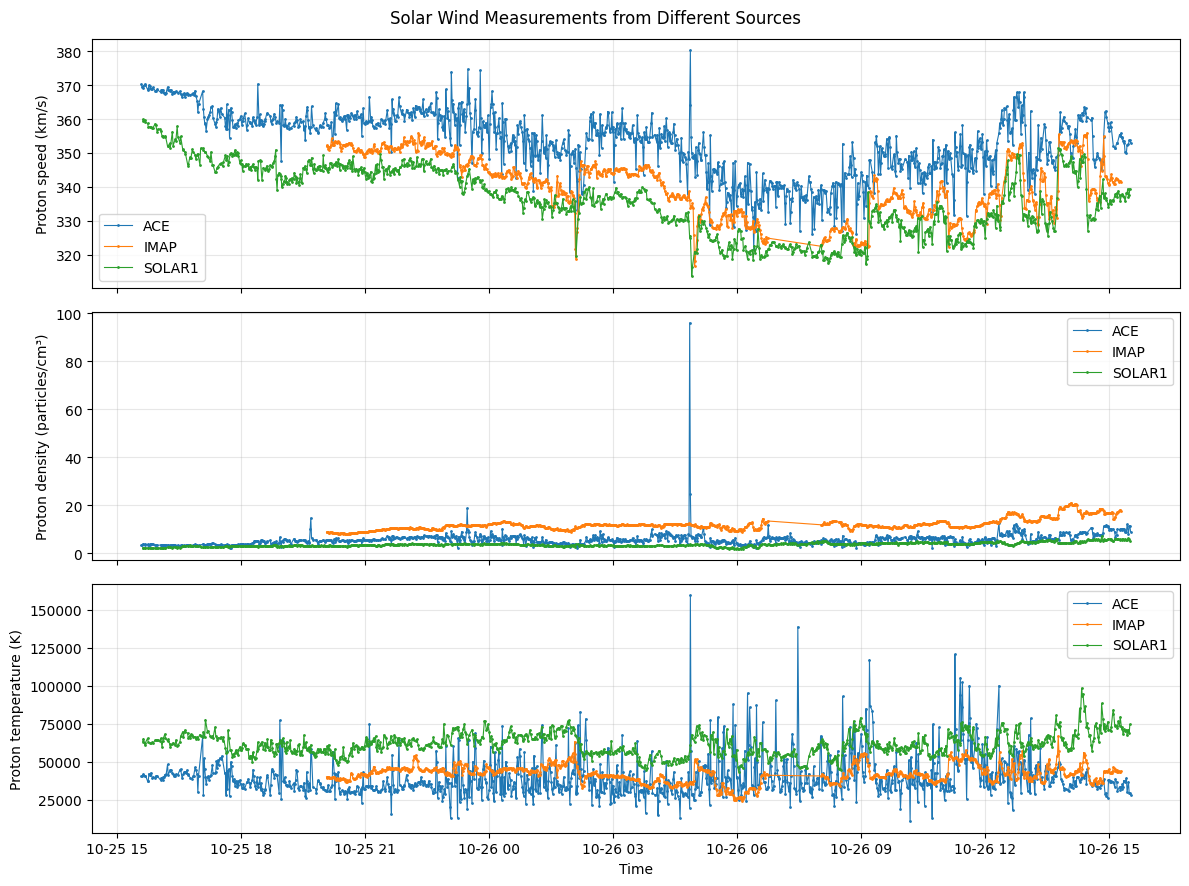

In [ ]:

# STEP 2: Plot the three solar wind measurements over time

import matplotlib.pyplot as plt

plot_df = df.sort_values("time_tag").copy()

measurements = [
    ("proton_speed", "Proton speed (km/s)"),
    ("proton_density", "Proton density (particles/cm³)"),
    ("proton_temperature", "Proton temperature (K)")
]

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

for ax, (column, label) in zip(axes, measurements):
    for source, group in plot_df.groupby("source"):
        group = group.dropna(subset=["time_tag", column])
        ax.plot(group["time_tag"], group[column],
                marker=".", markersize=2, linewidth=0.8,
                label=source)

    ax.set_ylabel(label)
    ax.legend()
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Time")
fig.suptitle("Solar Wind Measurements from Different Sources")
plt.tight_layout()
plt.show()


In [ ]:

# STEP 3: Check data quality

print("Missing values in key measurements:")
print(df[[
    "proton_speed",
    "proton_density",
    "proton_temperature"
]].isna().sum())

print("\nRepeated timestamps:", df["time_tag"].duplicated().sum())

print("\nMeasurements by source:")
print(df["source"].value_counts())


Missing values in key measurements:
proton_speed          3
proton_density        3
proton_temperature    3
dtype: int64

Repeated timestamps: 928

Measurements by source:
source
ACE       1183
IMAP      1073
SOLAR1    1033
Name: count, dtype: int64


In [ ]:

# STEP 4: Inspect repeated timestamps

print("Example records with repeated timestamps:")

repeated = df[df["time_tag"].duplicated(keep=False)]

display(
    repeated[
        ["time_tag", "source", "proton_speed",
         "proton_density", "proton_temperature"]
    ].sort_values("time_tag").head(15)
)


Example records with repeated timestamps:


,time_tag,source,proton_speed,proton_density,proton_temperature
3286,2026-10-25 15:37:00,ACE,369.20,3.63,40851.0
3285,2026-10-25 15:37:00,SOLAR1,359.90,2.26,63166.0
3283,2026-10-25 15:38:00,SOLAR1,359.30,2.29,65171.0
3284,2026-10-25 15:38:00,ACE,369.80,3.76,41664.0
3281,2026-10-25 15:40:00,SOLAR1,359.70,2.24,61010.0
3282,2026-10-25 15:40:00,ACE,370.28,3.59,40214.0
3279,2026-10-25 15:41:00,SOLAR1,359.10,2.24,62533.0
3280,2026-10-25 15:41:00,ACE,370.07,3.69,40737.0
3277,2026-10-25 15:44:00,SOLAR1,358.70,2.16,65333.0
3278,2026-10-25 15:44:00,ACE,368.71,3.63,37144.0


In [ ]:

# STEP 5: Prepare ACE observations for analysis

ace_df = df[df["source"] == "ACE"].copy()

ace_df = ace_df.sort_values("time_tag")

# Keep only the time and three main measurements
ace_df = ace_df[
    ["time_tag", "proton_speed",
     "proton_density", "proton_temperature"]
]

print("ACE dataset dimensions:", ace_df.shape)
print("\nMissing values:")
print(ace_df.isna().sum())

print("\nFirst five ACE observations:")
display(ace_df.head())


ACE dataset dimensions: (1183, 4)

Missing values:
time_tag              0
proton_speed          0
proton_density        0
proton_temperature    0
dtype: int64

First five ACE observations:


,time_tag,proton_speed,proton_density,proton_temperature
3288,2026-10-25 15:35:00,370.24,3.28,40450.0
3287,2026-10-25 15:36:00,369.43,3.50,40328.0
3286,2026-10-25 15:37:00,369.20,3.63,40851.0
3284,2026-10-25 15:38:00,369.80,3.76,41664.0
3282,2026-10-25 15:40:00,370.28,3.59,40214.0


In [ ]:

# STEP 6: Check gaps between ACE observations

ace_df["time_gap_minutes"] = (
    ace_df["time_tag"].diff().dt.total_seconds() / 60
)

print("Time gap in minutes between consecutive observations:")
print(ace_df["time_gap_minutes"].value_counts().sort_index())

print("\nLargest time gaps:")
display(
    ace_df.nlargest(10, "time_gap_minutes")[
        ["time_tag", "time_gap_minutes"]
    ]
)


Time gap in minutes between consecutive observations:
time_gap_minutes
1.0    984
2.0    158
3.0     30
4.0      6
5.0      2
6.0      2
Name: count, dtype: int64

Largest time gaps:


,time_tag,time_gap_minutes
3179,2026-10-25 17:04:00,6.0
129,2026-10-26 14:34:00,6.0
3255,2026-10-25 16:03:00,5.0
841,2026-10-26 10:04:00,5.0
3140,2026-10-25 17:36:00,4.0
3041,2026-10-25 18:42:00,4.0
2987,2026-10-25 19:16:00,4.0
2937,2026-10-25 19:48:00,4.0
359,2026-10-26 13:02:00,4.0
298,2026-10-26 13:26:00,4.0


In [ ]:

# STEP 7: Test linear interpolation on hidden measurements

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error

# Use ACE proton speed, arranged at one-minute intervals
speed = (
    ace_df.drop_duplicates("time_tag")
    .set_index("time_tag")["proton_speed"]
    .sort_index()
)

full_time = pd.date_range(
    start=speed.index.min(),
    end=speed.index.max(),
    freq="1min"
)

speed = speed.reindex(full_time)

# Only test values that were actually measured
known_positions = np.flatnonzero(speed.notna().to_numpy())

# Hide 15% of known measurements at random
rng = np.random.default_rng(42)
n_hide = max(1, int(0.15 * len(known_positions)))
hidden_positions = rng.choice(
    known_positions, size=n_hide, replace=False
)

true_values = speed.iloc[hidden_positions].copy()
test_speed = speed.copy()
test_speed.iloc[hidden_positions] = np.nan

# Estimate the hidden values using interpolation
predictions = test_speed.interpolate(
    method="linear", limit_area="inside"
).iloc[hidden_positions]

# Compare predictions with the real measurements
valid = predictions.notna()

mae = mean_absolute_error(
    true_values[valid],
    predictions[valid]
)

print("Hidden measurements:", n_hide)
print("Successfully predicted:", int(valid.sum()))
print("Mean Absolute Error:", round(mae, 2), "km/s")


Hidden measurements: 177
Successfully predicted: 177
Mean Absolute Error: 2.52 km/s


In [ ]:

# STEP 8: Compare interpolation with forward fill

# Recreate the same hidden measurements
test_speed = speed.copy()
test_speed.iloc[hidden_positions] = np.nan

# Method 1: Linear interpolation
interpolation_predictions = test_speed.interpolate(
    method="linear", limit_area="inside"
).iloc[hidden_positions]

# Method 2: Forward fill
forward_fill_predictions = test_speed.ffill().iloc[hidden_positions]

# Compare both methods on the same hidden values
true_values = speed.iloc[hidden_positions]

interpolation_mae = mean_absolute_error(
    true_values, interpolation_predictions
)

forward_fill_mae = mean_absolute_error(
    true_values, forward_fill_predictions
)

print("Prediction comparison for proton speed")
print("---------------------------------------")
print("Linear interpolation MAE:",
      round(interpolation_mae, 2), "km/s")
print("Forward fill MAE:",
      round(forward_fill_mae, 2), "km/s")


Prediction comparison for proton speed
---------------------------------------
Linear interpolation MAE: 2.52 km/s
Forward fill MAE: 3.24 km/s
